# Week 8: Control variables
**DS-UA 201 · Fall 2026**  
**Center for Data Science, New York University**

**TA: Xiang Gao**

Oct 30, 2026

[Open in Colab](https://colab.research.google.com/github/xgao0o/DS-UA_201-Causal-Inference-Fall-2026/blob/main/labs/8-Control_Variables.ipynb) (available after publication to the repository).


All datasets and scenarios below are **synthetic teaching examples**, not empirical findings about college or income. No external data files or downloads are required.


## Setup
Run cells from top to bottom, or choose **Restart Kernel and Run All Cells**. We use NumPy, pandas, Matplotlib, and statsmodels. Each simulation has its own fixed random seed. See the [course README](../README.md) for local installation; in Colab, upload this notebook and run all cells.


In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (7, 4), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREEN = "#526F8A", "#B85C38", "#477766"


## 1. Why use control variables?
In observational data, people who receive a treatment may differ from those who do not in ways that also affect the outcome. A raw comparison can therefore mix the treatment effect with differences in other causes of the outcome.

Let $S\in\{0,1\}$ denote treatment, $Y$ the observed outcome, and $C$ an observed **pretreatment** characteristic. A **control variable** is a variable we condition on when making a comparison or include as an adjustment variable in a regression. Conditioning on $C$ means comparing observations at the same value of $C$.

**Motivating example: college and income.** Suppose family resources before college affect both whether someone attends college and their later income. Family resources are then a **confounder**: a common cause of treatment and outcome. Comparing college attendees with nonattendees who have the same family resources can remove this particular source of differences.

The key question is whether the chosen controls are **sufficient** to make the groups comparable in their potential outcomes—the outcomes they would have under each treatment level. Controlling for one measured variable does not address every possible source of confounding. We will state the required assumptions, then compare within-group adjustment with regression using synthetic data where the true effect is known.

### Exercise 1: choose the comparison
In the college–income example, identify $S$, $Y$, and a candidate control $C$. Why might the overall income difference fail to equal the causal effect of college? Does measuring $C$ before college guarantee that it is a sufficient control?

<details><summary>Answer</summary>

$S$ is college attendance, $Y$ is later income, and $C$ is family resources measured before college. Higher-resource individuals may be more likely to attend college and may have higher incomes even without college, so the overall difference can include confounding. Comparing within family-resource groups addresses the stated common-cause path. Pretreatment measurement alone does not establish sufficiency: other common causes may remain unmeasured or inadequately controlled. The causal interpretation requires assumptions beyond adding $C$ to a regression.

</details>


## 2. Independence and conditional independence
For any sets of values $A$ and $B$, random variables $X$ and $Y$ are independent if

$$P(X\in A,Y\in B)=P(X\in A)P(Y\in B).$$

Knowing $X$ does not change the distribution of $Y$. With finite second moments, independence implies $\operatorname{Cov}(X,Y)=0$. The converse is false: zero covariance need not mean independence.

For example, if $X$ is equally likely to be $-1,0,1$ and $Y=X^2$, then $\mathbb E[X]=\mathbb E[X^3]=0$, so $\operatorname{Cov}(X,Y)=0$. Yet knowing $X$ determines $Y$.

**Conditional independence** $Y\perp Z\mid X$ means that, for values $x$ in the support,

$$P(Y\in A,Z\in B\mid X=x)
=P(Y\in A\mid X=x)P(Z\in B\mid X=x).$$

Knowing $Z$ adds no distributional information about $Y$ once $X$ is known. Marginal dependence can coexist with conditional independence.


In [2]:
# Independent dice: the population covariance is zero; its sample estimate need not be.
dice_rng = np.random.default_rng(8201)
die_1 = dice_rng.integers(1, 7, 1000)
die_2 = dice_rng.integers(1, 7, 1000)
print(f"Sample covariance of independent dice: {np.cov(die_1, die_2, ddof=1)[0, 1]:.3f}")

# An exact three-point population: uncorrelated but dependent.
x_values = np.array([-1., 0., 1.])
y_values = x_values ** 2
probabilities = np.full(3, 1 / 3)
ex = probabilities @ x_values
ey = probabilities @ y_values
population_covariance = probabilities @ (x_values * y_values) - ex * ey
print(f"Population covariance of X and X squared: {population_covariance:.3f}")


Sample covariance of independent dice: 0.061
Population covariance of X and X squared: 0.000


### A common cause creates marginal dependence

$$X\sim\operatorname{Uniform}\{1,\ldots,9\},\qquad
Y=2X+\varepsilon_Y,\qquad Z=2X+\varepsilon_Z.$$

The two errors are independent standard normal variables, also independent of $X$. Thus $Y$ and $Z$ share a common cause $X$ but are independent **given $X$**, because their remaining randomness comes from independent errors. Marginally, $\operatorname{Cov}(Y,Z)=4\operatorname{Var}(X)=80/3$; conditionally, $\operatorname{Cov}(Y,Z\mid X=x)=0$.


In [4]:
ci_rng = np.random.default_rng(8202)
x = ci_rng.integers(1, 10, 1800)
ci_data = pd.DataFrame({
    "X": x,
    "Y": 2 * x + ci_rng.normal(size=len(x)),
    "Z": 2 * x + ci_rng.normal(size=len(x)),
})
covariance_rows = [{"Group": "All observations", "n": len(ci_data),
                    "Sample covariance(Y, Z)": ci_data.Y.cov(ci_data.Z)}]
for value, group in ci_data.groupby("X"):
    covariance_rows.append({"Group": f"X = {value}", "n": len(group),
                            "Sample covariance(Y, Z)": group.Y.cov(group.Z)})
display(pd.DataFrame(covariance_rows).set_index("Group").round(3))


,n,"Sample covariance(Y, Z)"
Group,,
All observations,1800,26.236
X = 1,204,-0.013
X = 2,223,-0.120
X = 3,202,0.040
X = 4,200,0.106
X = 5,210,-0.041
X = 6,198,-0.017
X = 7,200,-0.078
X = 8,181,0.139


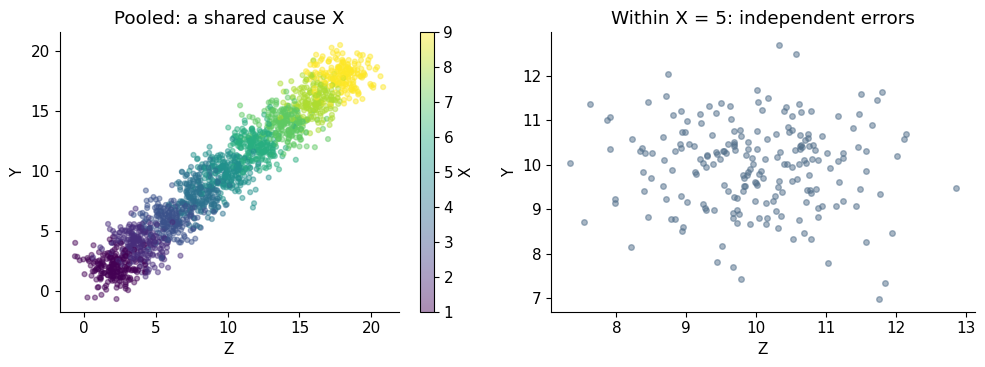

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
points = axes[0].scatter(ci_data.Z, ci_data.Y, c=ci_data.X, cmap="viridis",
                         s=12, alpha=0.45)
axes[0].set(xlabel="Z", ylabel="Y", title="Pooled: a shared cause X")
fig.colorbar(points, ax=axes[0], label="X")
within = ci_data.loc[ci_data.X == 5]
axes[1].scatter(within.Z, within.Y, color=BLUE, s=16, alpha=0.5)
axes[1].set(xlabel="Z", ylabel="Y", title="Within X = 5: independent errors")
fig.tight_layout()
plt.show()


In [6]:
# A linear association diagnostic for this known simulation.
pooled_ci = smf.ols("Y ~ Z", data=ci_data).fit()
adjusted_ci = smf.ols("Y ~ Z + X", data=ci_data).fit()
display(pd.DataFrame({
    "Model": ["Y ~ Z", "Y ~ Z + X"],
    "Coefficient on Z": [pooled_ci.params["Z"], adjusted_ci.params["Z"]],
}).set_index("Model").round(3))


,Coefficient on Z
Model,
Y ~ Z,0.964
Y ~ Z + X,-0.009


### What the diagnostic can and cannot show
The adjusted coefficient is near zero here because we specified independent errors and the correct conditional means. Sample covariances need not be exactly zero. Neither a small coefficient nor a large p-value establishes full conditional independence: nonlinear dependence can remain, and a test may have low power.

In a causal study, we also cannot observe both potential outcomes for anyone. Unmeasured causes cannot simply be regressed on treatment to test away confounding. Design knowledge supports the assumption; observed-data diagnostics may reveal problems but do not prove it.

### Exercise 2: zero association after adjustment
A researcher finds a treatment coefficient of 0.01 with $p=0.80$ when predicting one pretreatment variable using treatment and controls. Has the researcher established conditional independence for the outcome?

<details><summary>Answer</summary>

No. This checks a particular association for one measured variable under a chosen model. It neither proves distributional independence for that variable nor establishes independence between treatment and all potential outcomes. Unmeasured confounding, nonlinear relationships, and low statistical power remain possible. In our simulation, independence follows from the data-generating mechanism, not the fitted coefficient.

</details>


## 3. All-causes model and identification
Let $Y_i(s)$ be person $i$'s potential outcome under treatment level $s$. Write $Y_i(s)=Y(s,U_i)$, where $U_i$ collects other causes of the outcome. Some components of $U_i$ may be observed; others may be unobserved. Hold the same person's background factors fixed when comparing $Y_i(1)$ and $Y_i(0)$.

Define $\Delta=Y(1)-Y(0)$. The population causal parameters are

$$\operatorname{ATE}=\mathbb E[\Delta],\qquad
\operatorname{ATT}=\mathbb E[\Delta\mid S=1],\qquad
\operatorname{ATU}=\mathbb E[\Delta\mid S=0].$$

The fundamental problem is that we observe only one potential outcome per person. An observed mean difference is therefore not automatically any of these causal parameters.

For discrete pretreatment controls $C$, consider these assumptions:

1. **Consistency and a well-defined treatment:** $Y=Y(S)$, with no interference between units in our examples.
2. **Conditional exchangeability:** $(Y(0),Y(1))\perp S\mid C$. Within each value of $C$, treated and untreated people have the same distribution of potential outcomes. Their observed outcomes may still differ because treatment has an effect.
3. **Overlap (positivity):** $0<P(S=1\mid C=c)<1$ for every stratum in the target population.

For estimation, we also need data that represent the target population, or appropriate sampling adjustments. Here simulated rows are independent draws from the stated population.


### Parameter → identification → estimator → estimate
By iterated expectations, exchangeability, and consistency,

$$\begin{aligned}
\operatorname{ATE}
&=\sum_c P(C=c)\{\mathbb E[Y(1)\mid C=c]-\mathbb E[Y(0)\mid C=c]\}\\
&=\sum_c P(C=c)\{\mathbb E[Y\mid S=1,C=c]-\mathbb E[Y\mid S=0,C=c]\}.
\end{aligned}$$

This **identification formula** expresses the causal parameter in terms of the observed-data distribution. Overlap makes both conditional means available.


### How the linear regression model fits in
We use an additive, constant-effect structural model:

$$Y(s,U)=\alpha_0+\tau s+U.$$

This equation alone does **not** imply independence. Suppose additionally that $S\perp U\mid C$ and that the conditional mean is linear, $\mathbb E[U\mid C]=\gamma_0+\gamma_1C$. Define

$$V=U-\mathbb E[U\mid C].$$

Then

$$Y=(\alpha_0+\gamma_0)+\tau S+\gamma_1C+V,
\qquad \mathbb E[V\mid S,C]=0.$$

It does not require $V$ to be fully independent of $(S,C)$. Linearity of $\mathbb E[U\mid C]$ is an **additional modeling assumption**, not a consequence of conditional independence. For binary $C$, an intercept and $C$ can represent any conditional mean function of $C$.

If effects vary or the conditional mean is nonlinear, simply including additive linear controls may not estimate the ATE. We return to varying effects in the optional extension.


## 4. College and income: a worked simulation
Here is a college–income example with potential outcomes:

- $C=1$: higher family resources before college; $C=0$: lower family resources.
- $S=1$: attends college; $S=0$: does not attend.
- $Y$: annual income in synthetic dollars.

Higher family resources affect both college attendance and income. Here family resources are the observed control $C$; the all-causes collection includes $C$ and an independent income shock $\varepsilon$. The diagram encodes our assumed mechanism; the data alone do not establish these arrows.


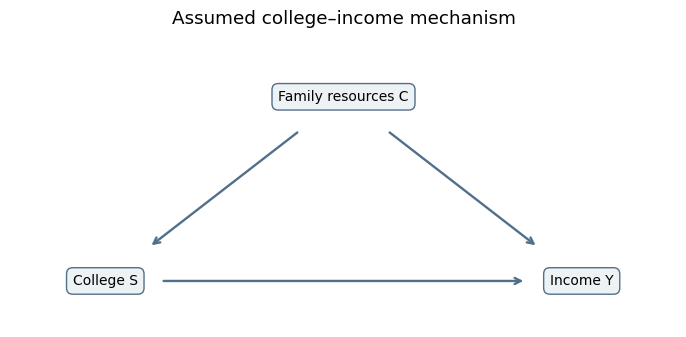

In [7]:
# Draw locally: no NetworkX dependency or remote image needed.
def draw_graph(ax, nodes, edges, title):
    for label, (x, y) in nodes.items():
        ax.text(x, y, label, ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.45", fc="#EDF2F5", ec=BLUE))
    for start, end in edges:
        ax.annotate("", xy=nodes[end], xytext=nodes[start],
                    arrowprops=dict(arrowstyle="->", color=BLUE, lw=1.7,
                                    shrinkA=42, shrinkB=42))
    ax.set(xlim=(-0.2, 1.2), ylim=(-0.25, 1.35), title=title)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(7, 3.5))
nodes = {"Family resources C": (0.5, 1), "College S": (0, 0), "Income Y": (1, 0)}
draw_graph(ax, nodes, [("Family resources C", "College S"),
                       ("Family resources C", "Income Y"),
                       ("College S", "Income Y")], "Assumed college–income mechanism")
fig.tight_layout()
plt.show()


### Define potential outcomes before assigning treatment
Generate $C\sim\operatorname{Bernoulli}(0.4)$ and an independent $\varepsilon\sim N(0,5000^2)$, then define

$$Y(0)=50000+20000C+\varepsilon,\qquad Y(1)=Y(0)+30000.$$

Assign treatment with probability $P(S=1\mid C)=0.3+0.4C$ using randomness independent of $\varepsilon$. Observe $Y=SY(1)+(1-S)Y(0)$.

Thus treatment is associated with baseline income marginally, but is independent of potential outcomes given $C$. Both family-resource groups have overlap. Every individual's effect is $30000$, so the **population** ATE, ATT, and ATU all equal $30000$. Constant effects make these three equal even though college attendance depends on family resources.

This is a toy observational assignment mechanism, not evidence that controlling for family resources suffices in a real study of college.


In [8]:
college_rng = np.random.default_rng(8203)
n = 1000
family = college_rng.binomial(1, 0.4, n)
noise = college_rng.normal(0, 5000, n)
y0 = 50000 + 20000 * family + noise
y1 = y0 + 30000
prob_college = 0.3 + 0.4 * family
college = college_rng.binomial(1, prob_college)
income = np.where(college == 1, y1, y0)

# The analyst sees only these columns.
college_data = pd.DataFrame({"C": family, "S": college, "Y": income})
# Keep both potential outcomes separate for simulation checks only.
simulation_truth = pd.DataFrame({"Y0": y0, "Y1": y1})
assert np.allclose(income, college * y1 + (1 - college) * y0)
assert np.allclose(y1 - y0, 30000)
display(college_data.head().round(2))


,C,S,Y
0,0,0,52908.26
1,1,1,99734.58
2,1,1,104243.72
3,0,1,88970.50
4,1,1,99271.72


In [9]:
# Oracle calculations use information unavailable in a real study.
individual_effect = simulation_truth.Y1 - simulation_truth.Y0
oracle = pd.Series({
    "Finite-sample average effect": individual_effect.mean(),
    "Finite treated-group average effect": individual_effect[college == 1].mean(),
    "Finite untreated-group average effect": individual_effect[college == 0].mean(),
}, name="Synthetic dollars")
display(oracle.to_frame().round(2))

raw_gap = (college_data.loc[college_data.S == 1, "Y"].mean()
           - college_data.loc[college_data.S == 0, "Y"].mean())
baseline_gap = y0[college == 1].mean() - y0[college == 0].mean()
assert np.isclose(raw_gap, individual_effect[college == 1].mean() + baseline_gap)
print(f"Raw observed mean difference: ${raw_gap:,.2f}")
print(f"Treated-minus-untreated baseline Y(0) gap: ${baseline_gap:,.2f}")


,Synthetic dollars
Finite-sample average effect,30000.0
Finite treated-group average effect,30000.0
Finite untreated-group average effect,30000.0


Raw observed mean difference: $38,323.78
Treated-minus-untreated baseline Y(0) gap: $8,323.78


The oracle table contains **finite-group averages**, computed from both potential outcomes. They equal the population parameters here only because every effect is constant. The observed difference includes a baseline composition difference.

### Compare within family-resource strata, then standardize
First inspect counts: we need both college groups at each value of $C$. Then compute the two within-stratum differences and average them with sample stratum shares.


In [10]:
stratum_counts = pd.crosstab(college_data.C, college_data.S).reindex(index=[0, 1], columns=[0, 1])
stratum_means = college_data.groupby(["C", "S"]).Y.mean().unstack("S")
assert (stratum_counts.to_numpy() > 0).all()
stratum_effects = stratum_means[1] - stratum_means[0]
target_weights = college_data.C.value_counts(normalize=True).sort_index()
standardized_ate = (target_weights * stratum_effects).sum()
stratum_table = pd.DataFrame({
    "n: S=0": stratum_counts[0], "n: S=1": stratum_counts[1],
    "Mean Y: S=0": stratum_means[0], "Mean Y: S=1": stratum_means[1],
    "Within-stratum difference": stratum_effects, "Target weight": target_weights,
})
stratum_table.index.name = "Family resources C"
display(stratum_table.round(2))
print(f"Standardized ATE estimate: ${standardized_ate:,.2f}")


,n: S=0,n: S=1,Mean Y: S=0,Mean Y: S=1,Within-stratum difference,Target weight
Family resources C,,,,,,
0,459,168,49683.96,79574.20,29890.24,0.63
1,120,253,69994.93,100612.65,30617.72,0.37


Standardized ATE estimate: $30,161.59


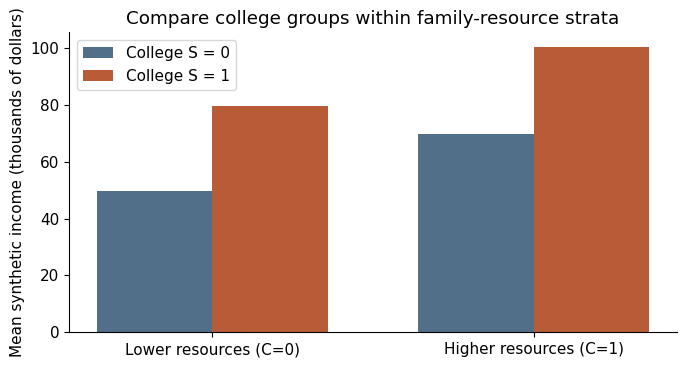

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
positions = np.arange(2)
for s, offset, color in [(0, -0.18, BLUE), (1, 0.18, ORANGE)]:
    ax.bar(positions + offset, stratum_means[s] / 1000, width=0.36,
           color=color, label=f"College S = {s}")
ax.set(xticks=positions, xticklabels=["Lower resources (C=0)", "Higher resources (C=1)"],
       ylabel="Mean synthetic income (thousands of dollars)",
       title="Compare college groups within family-resource strata")
ax.legend()
fig.tight_layout()
plt.show()


### Exercise 3: interpret the adjusted comparison
1. Why does the raw difference exceed the known effect in this simulation?
2. Why need the standardized estimate not equal exactly $30000$?
3. If $S=C$ for everyone, could the same within-stratum calculation identify the effect?

<details><summary>Answer</summary>

1. Higher-resource individuals are more likely to attend college and have higher untreated incomes. The raw difference combines the college effect with this baseline difference. Its exact realized error also includes sampling noise.
2. Treatment groups have different average noise within strata by chance. Identification is a population result; replacing expectations with sample means produces a random estimator.
3. No. If $S=C$, each stratum contains only one treatment arm, violating overlap. The missing within-stratum means cannot be learned from these comparisons. A regression including both $S$ and $C$ also has perfectly collinear regressors; collecting more observations under the same rule does not fix the problem.

</details>


## 5. Regression with controls
Compare two ordinary least squares (OLS) regressions:

$$Y_i=\beta_0+\beta_1 S_i+e_i,\qquad
Y_i=\theta_0+\theta_1 S_i+\theta_2 C_i+v_i.$$

With binary $S$ and an intercept, the first treatment coefficient equals the raw sample difference. The second includes a sufficient control and the correct conditional mean for **our stated constant-effect simulation**. Its treatment coefficient estimates $30000$.

We report HC2 heteroskedasticity-robust standard errors with approximate normal 95% intervals. These assume independent observations and suitable large-sample conditions. They address sampling uncertainty, not identification. A clustered assignment mechanism would call for uncertainty calculations that reflect those clusters.


In [12]:
unadjusted_fit = smf.ols("Y ~ S", data=college_data).fit(cov_type="HC2", use_t=False)
adjusted_fit = smf.ols("Y ~ S + C", data=college_data).fit(cov_type="HC2", use_t=False)
assert np.isclose(unadjusted_fit.params["S"], raw_gap)
regression_rows = []
for name, fit in [("Without controls", unadjusted_fit), ("With family resources", adjusted_fit)]:
    lower, upper = fit.conf_int().loc["S"]
    regression_rows.append({"Model": name, "Coefficient on S": fit.params["S"],
                            "HC2 SE": fit.bse["S"], "95% lower": lower, "95% upper": upper})
regression_results = pd.DataFrame(regression_rows).set_index("Model")
display(regression_results.round(2))
print(f"Known population ATE: $30,000.00; standardized estimate: ${standardized_ate:,.2f}")


,Coefficient on S,HC2 SE,95% lower,95% upper
Model,,,,
Without controls,38323.78,685.08,36981.04,39666.51
With family resources,30179.96,351.20,29491.62,30868.30


Known population ATE: $30,000.00; standardized estimate: $30,161.59



### Exercise 4: a precise but wrong answer
A much larger dataset gives an uncontrolled coefficient close to the population raw difference above, with a very small standard error. Does this establish the college effect? Would using robust standard errors or adding arbitrary predictors fix the problem?

<details><summary>Answer</summary>

No. More data estimate the unadjusted association more precisely, but that association differs from the causal effect. Robust standard errors do not remove omitted-variable bias. In this constructed example, conditioning on family resources suffices because of the specified assignment mechanism and independent noise. Arbitrary predictors need not address confounding and can introduce other biases. In a real college study, the sufficiency of family resources would need a separate argument.

</details>


## 6. Which variables should we control for?
Choose controls using the assignment mechanism, temporal ordering, and substantive knowledge. A **confounder** is a common cause of treatment and outcome. A **mediator** lies on a causal pathway from treatment to outcome. A **collider** is a common effect of two variables along a path.

| Assumed structure | Implication for estimating the total effect of $S$ on $Y$ |
|:--|:--|
| $S\leftarrow C\rightarrow Y$ | Controlling for a sufficient set of pretreatment common causes can remove confounding. |
| $S\rightarrow M\rightarrow Y$ | Controlling for mediator $M$ blocks part of the total effect. A direct-effect question requires additional assumptions. |
| $S\rightarrow K\leftarrow U\rightarrow Y$ | Controlling for collider $K$ can create an association between $S$ and $U$, introducing bias. |

![Indep](https://www.cs.cmu.edu/~15281-f23/coursenotes/bayesnets/images/bayes_ball.png)

Being measured before treatment is useful but **not sufficient**: a pretreatment variable can also be a collider on another path. High predictive accuracy, a large $R^2$, or statistical significance does not determine a valid adjustment set. More controls are not automatically better.

### Exercise 5: choose controls and state the target
We want the **total effect** of college attendance on later income. Consider three candidate controls:

1. Family resources before college, which affect both college attendance and later income.
2. Skills acquired during college, through which attendance affects income.
3. Follow-up survey participation, which is affected by college attendance and by motivation; motivation also affects income.

Which variable addresses the stated confounding path? What goes wrong with the other two? What must you still argue after choosing a control?

<details><summary>Answer</summary>

Family resources address the specified common-cause path, but we still need a sufficient adjustment set overall. Acquired skills are a mediator, so controlling for them blocks part of the total effect. Survey participation is a collider on the path college attendance → participation ← motivation → income; conditioning on it, including by analyzing respondents only, can open that path. If outcomes are missing for nonrespondents, ignoring participation as a regressor does not by itself repair selection: the response process needs attention. We must justify conditional exchangeability, overlap, consistency/no interference, the target population, and the estimation model.

</details>

